# 04 · Is the residual actually mean reverting?

Separate a stationary spread, a fading shock, and a profitable trading signal.

Run this notebook from top to bottom. It is independent of the execution state of other notebooks.

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown
from btc_nasdaq.config import project_root, load_config
from btc_nasdaq.research import research_context, run_period
from btc_nasdaq.plotting import set_theme, save_figure, shade_holdout, PALETTE
from btc_nasdaq.data import sha256

set_theme()
pd.options.display.float_format = "{:,.4f}".format
ROOT = project_root()
c = research_context(ROOT)
cfg, prices, returns = c["cfg"], c["prices"], c["returns"]
betas, beta, signal = c["betas"], c["beta"], c["signal"]
HOLDOUT = cfg["validation"]["holdout_start"]
summary_path = ROOT / "reports/tables/summary.json"
if not summary_path.exists():
    raise RuntimeError("Run uv run python scripts/run_research.py before executing the notebooks.")
run_record = json.loads(summary_path.read_text())
if (run_record["config_sha256"] != sha256(ROOT / "configs/research.toml") or
    run_record["data_sha256"] != sha256(ROOT / "data/processed/aligned_prices.parquet")):
    raise RuntimeError("Summary tables are stale. Re-run scripts/run_research.py.")
display(Markdown(f"**Data:** {prices.index.min():%Y-%m-%d} to {prices.index.max():%Y-%m-%d} "
                 f"· **{len(prices):,} synchronized sessions** · BTC-USD / QQQ · "
                 f"**Fixed baseline:** {cfg['strategy']['model']}"))

**Data:** 2018-01-02 to 2026-11-06 · **2,225 synchronized sessions** · BTC-USD / QQQ · **Fixed baseline:** ewma_63

## First test a fixed relationship in log prices

Fit $\log P^{BTC}_t=a+b\log P^{QQQ}_t+u_t$ on training data only and freeze a and b for later
periods. Use the Engle–Granger residual-based test for training cointegration: an ordinary ADF
p-value on an estimated training residual has the wrong null distribution. Later fixed-coefficient
spread ADF/KPSS tests are diagnostics, subject to breaks and low power.

**Nulls:** Engle–Granger and ADF: no cointegration / unit root. KPSS: level stationarity.
Failure to reject is not proof. ADF on returns is usually unsurprising and says little about
level mean reversion. The log-price slope is not the return-beta hedge ratio.

train_n                                                               1008
intercept                                                          -3.8158
log_price_coefficient                                               2.4557
engle_granger_p                                                     0.1111
note                     Log-price slope is NOT the minimum-variance re...
Name: Training Engle–Granger model, dtype: object

,n,adf_p,kpss_p,kpss_boundary
Train,1008,0.0344,0.0324,
Validation,501,0.3425,0.0100,The test statistic is outside of the range of ...
Holdout,716,0.8056,0.0100,The test statistic is outside of the range of ...


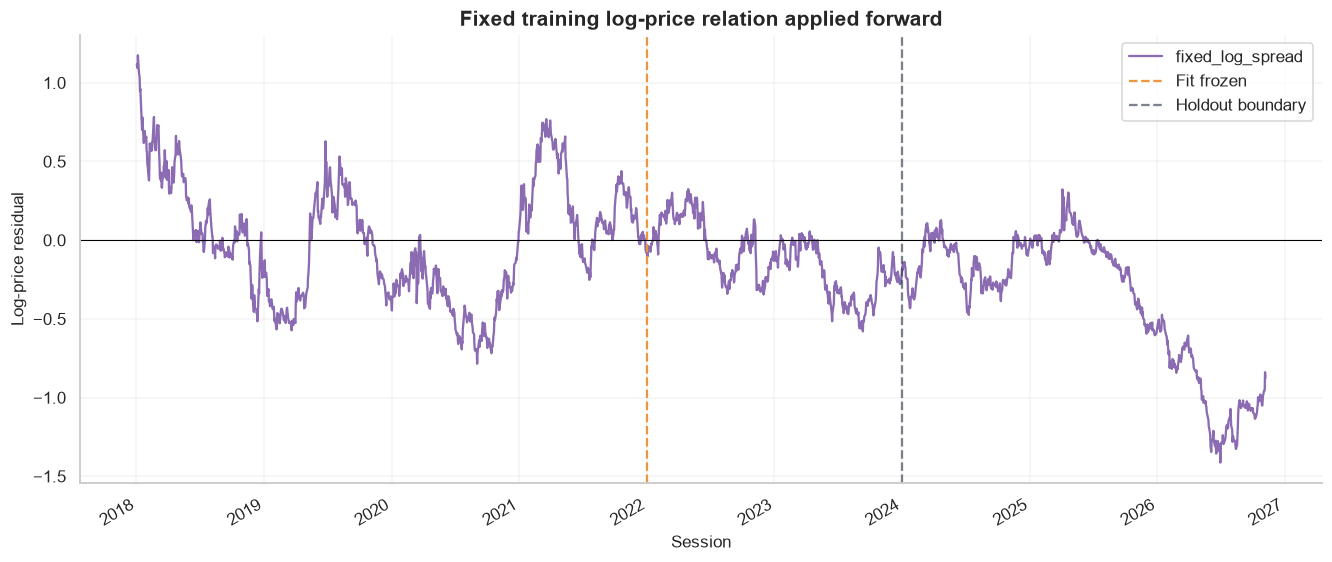

In [2]:
from btc_nasdaq.diagnostics import fixed_log_spread, stationarity, ou_diagnostic, predictive_regression
from statsmodels.graphics.tsaplots import plot_acf
spread, eg = fixed_log_spread(prices, cfg["validation"]["train_end"])
display(pd.Series(eg, name="Training Engle–Granger model"))
pieces = {"Train": spread.loc[:cfg["validation"]["train_end"]],
          "Validation": spread.loc["2022":"2023"], "Holdout": spread.loc[HOLDOUT:]}
display(pd.DataFrame({name: stationarity(s) for name, s in pieces.items()}).T)
fig, ax = plt.subplots(figsize=(12, 5))
spread.plot(ax=ax, color=PALETTE[3])
ax.axhline(0, color="black", lw=.7)
ax.axvline(pd.Timestamp("2022-01-01"), color=PALETTE[1], linestyle="--", label="Fit frozen")
shade_holdout(ax, HOLDOUT)
ax.set(title="Fixed training log-price relation applied forward", ylabel="Log-price residual", xlabel="Session")
ax.legend()
save_figure(fig, ROOT, "04_fixed_log_spread")
plt.show()

,phi,phi_low,phi_high,half_life_sessions,phi_ci_below_one,note
Train,0.9849,0.9763,0.9936,45.6643,True,Conditional AR(1) diagnostic; not a trading re...
Validation,0.9825,0.9673,0.9977,39.2692,True,Conditional AR(1) diagnostic; not a trading re...
Holdout,0.9976,0.9915,1.0037,287.8352,False,Conditional AR(1) diagnostic; not a trading re...


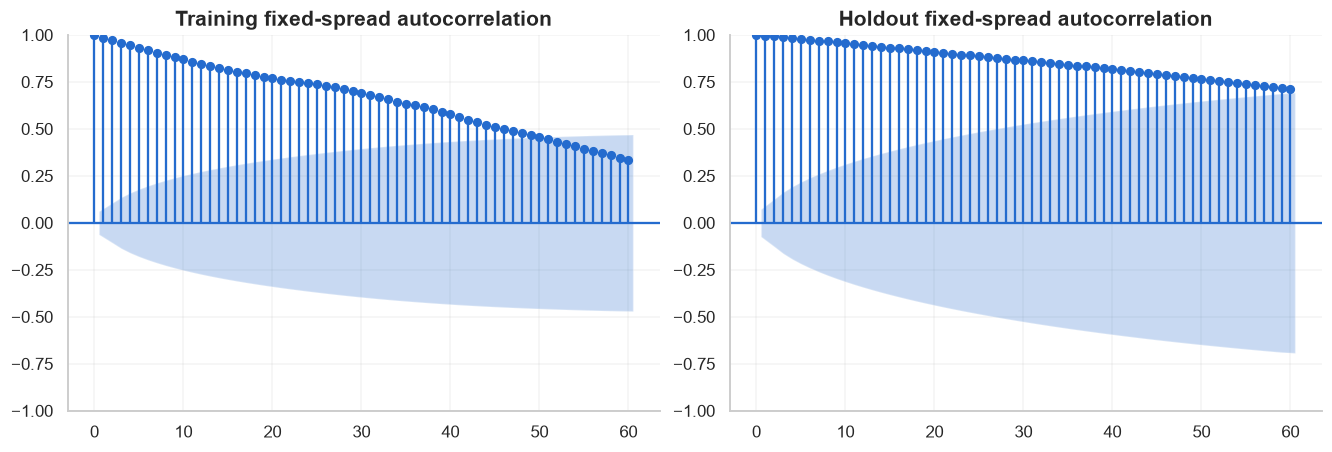

In [3]:
display(pd.DataFrame({name: ou_diagnostic(s) for name, s in pieces.items()}).T)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
plot_acf(pieces["Train"], lags=60, ax=axes[0], title="Training fixed-spread autocorrelation")
plot_acf(pieces["Holdout"], lags=60, ax=axes[1], title="Holdout fixed-spread autocorrelation")
plt.show()

The OU approximation is $u_{t+1}=c+\phi u_t+\epsilon_{t+1}$, with half-life
$-\log 2/\log\phi$ only when $0<\phi<1$. A finite fitted half-life is **not sufficient**:
near-unit-root estimates, estimated-spread inference, structural breaks, and the cointegration test
can contradict an appealing AR fit. HAC intervals here are approximate, not valid unit-root critical values.

## A separate hypothesis: fade a recent Bitcoin-specific shock

Define an observable return residual $e_t=r^{BTC}_t-\hat\beta_{t-1}r^{QQQ}_t$.
Sum 20 sessions, subtract a past-only expected sum and divide by a past volatility scale.
The normalization sample stops before that shock window; risk sizing uses volatility through t.
The scaling is approximate under autocorrelation and fat tails. A rolling sum mechanically forgets
old observations, so its tendency to cross zero cannot establish a tradable reversal.

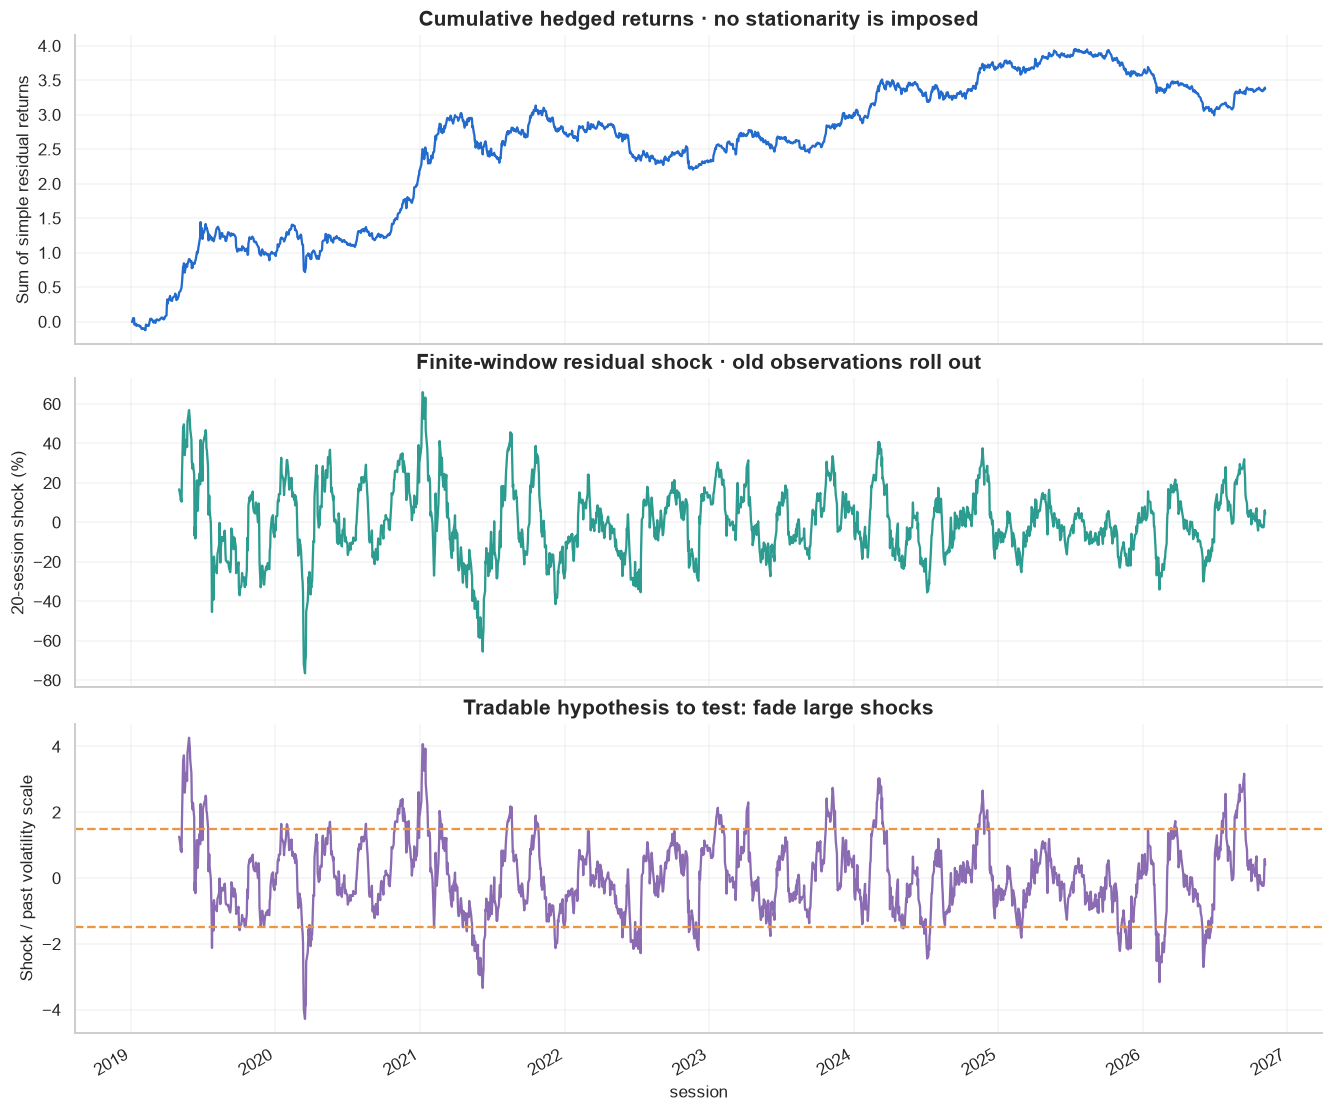

In [4]:
fig, axes = plt.subplots(3, 1, figsize=(12, 10), sharex=True)
signal.residual.cumsum().plot(ax=axes[0])
axes[0].set(title="Cumulative hedged returns · no stationarity is imposed", ylabel="Sum of simple residual returns")
signal.shock.mul(100).plot(ax=axes[1], color=PALETTE[2])
axes[1].set(title="Finite-window residual shock · old observations roll out", ylabel="20-session shock (%)")
signal.z.plot(ax=axes[2], color=PALETTE[3])
for zline in [-1.5, 1.5]:
    axes[2].axhline(zline, color=PALETTE[1], linestyle="--")
axes[2].set(title="Tradable hypothesis to test: fade large shocks", ylabel="Shock / past volatility scale")
plt.show()

## Does the shock predict returns after the execution delay?

At each decision time t, regress the return ending at t+2 (or the sum ending at t+2 through t+6)
on z_t, holding beta_t fixed for this diagnostic. Negative coefficients support the reversal direction.
HAC errors allow overlapping labels. These unscaled signal diagnostics omit execution costs and are
not a second backtest. Repeated comparisons need a fresh test or multiple-testing treatment.

,n,coefficient,hac_t,hac_p,r_squared
Train / 1 session,671.0000,0.0013,0.9722,0.3309,0.0015
Validation / 1 session,499.0000,-0.0004,-0.3139,0.7536,0.0001
Holdout / 1 session,714.0000,0.0013,1.3248,0.1852,0.0025
Holdout / 5 sessions,710.0000,0.0046,1.0880,0.2766,0.0066


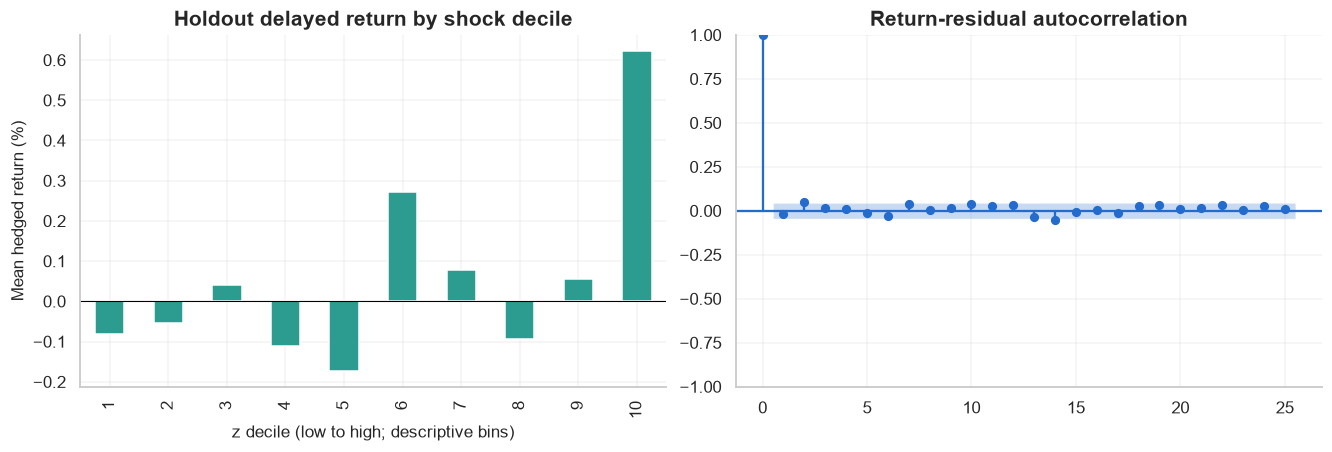

In [5]:
def delayed_future(start=None, end=None, horizon=1):
    # Shift WITHIN the segment so future labels cannot cross a split boundary.
    sample = returns.loc[start:end]
    b = beta.reindex(sample.index)
    return sum(sample.btc.shift(-k) - b*sample.qqq.shift(-k) for k in range(2, horizon+2))
future_1 = delayed_future(HOLDOUT)
future_5 = delayed_future(HOLDOUT, horizon=5)
predictive = pd.DataFrame({
    "Train / 1 session": predictive_regression(signal.z.loc[:"2021"], delayed_future(end="2021")),
    "Validation / 1 session": predictive_regression(signal.z.loc["2022":"2023"], delayed_future("2022", "2023")),
    "Holdout / 1 session": predictive_regression(signal.z.loc[HOLDOUT:], future_1.loc[HOLDOUT:]),
    "Holdout / 5 sessions": predictive_regression(signal.z.loc[HOLDOUT:], future_5.loc[HOLDOUT:]),
}).T
display(predictive)
frame = pd.DataFrame({"z": signal.z, "future": future_1}).loc[HOLDOUT:].dropna()
frame["decile"] = pd.qcut(frame.z, 10, labels=False, duplicates="drop") + 1
grouped = frame.groupby("decile").agg(mean_z=("z", "mean"), mean_return=("future", "mean"), n=("future", "size"))
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
(grouped.mean_return*100).plot.bar(ax=axes[0], color=PALETTE[2])
axes[0].axhline(0, color="black", lw=.7)
axes[0].set(title="Holdout delayed return by shock decile", xlabel="z decile (low to high; descriptive bins)", ylabel="Mean hedged return (%)")
plot_acf(signal.residual.dropna(), lags=25, ax=axes[1], title="Return-residual autocorrelation")
save_figure(fig, ROOT, "04_signal_diagnostics")
plt.show()

---
**Research notes / feedback**

- Observation worth following up:
- Assumption to change in the next experiment:
- Evidence that would change the conclusion:

Record changes in `docs/research_log.md`. Once you inspect a holdout, it is no longer untouched data for a new variant.